## 📈 How Much Should the Betting Market Count? A Four-Season Backtest
### *(Backtest of the Football League Simulator's market share, November 2026)*

**Competitions:** Premier League, Championship, La Liga, Bundesliga, Serie A, Ligue 1, Eredivisie, Primeira Liga, and Brasileirão\
**Question:** how much of each team's rating should come from the betting market, and should that share change as the season goes on?\
**Methods:** Poisson goal model, market-implied ratings (weighted ridge regression on expected goals worked back from odds), out-of-sample backtest, calibration\
**Author:** [Victoria Friss de Kereki](https://www.linkedin.com/in/victoria-friss-de-kereki/)

### Why look at this?

In October I started blending what recent betting prices say about each team into the ratings ([previous notebook](202610%20-%203%20-%20Market-Implied%20Team%20Strengths%20(Backtest).ipynb)). The test there picked **25% market**: at the end of 2025/26 more market made things worse, while at the start of 2026/27 the more market the better. The obvious next step was a share that falls as the season goes on.

Two things made me look again:

1. That test only had the odds saved by the daily run since 7 March 2026: one stretch at the end of one season and one at the start of the next.
2. Comparing those saved odds with another source turned up a bug: **some of them were taken while the match was being played.**

This notebook fixes both. It checks what the in-play prices did to the October result, then reruns the whole question on four seasons of clean pre-match odds from [football-data.co.uk](https://www.football-data.co.uk/data.php).

### 1. Setup

Everything comes from the production repo, `football-league-predictions`, cloned next to this one: `compute_final_probabilities`, `market_implied_ratings`, and `blend_ratings` in `3_probabilities.py`, unchanged.

In [1]:
import importlib.util, io, os, contextlib, warnings, subprocess, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson

warnings.filterwarnings("ignore")
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "football-league-predictions"))

def load_module(name, file):
    spec = importlib.util.spec_from_file_location(name, os.path.join(REPO, file))
    module = importlib.util.module_from_spec(spec)
    with contextlib.redirect_stdout(io.StringIO()):
        spec.loader.exec_module(module)
    return module

probabilities = load_module("probabilities", "3_probabilities.py")
processing = load_module("processing", "2_dataset_processing.py")
GREEN, GREY = "#1F8A3B", "#BBBBBB"

### 2. The bug: in-play prices in the saved odds

The odds API keeps returning a match while it's being played, and the twice-daily run saved whatever it returned. Those prices follow the score, not the teams. The market-implied ratings use each match's **latest** price, so an in-play price is exactly the one that gets used.

The fix (3 Nov 2026) keeps only matches that haven't kicked off, and removed the in-play rows from `data/odds_history/`. To see what they did, this loads the history **as it was before the fix**, straight from git, and flags every price saved after that same match had kicked off (up to 3 days later; a later meeting of the same two teams is a different fixture).

In [2]:
FIX_COMMIT = "4fd09179"
LEAGUES8 = ["premierleague_england", "championship_england", "seriea_italy", "laliga_spain",
            "bundesliga_germany", "ligue1_france", "eredivisie_netherlands", "primeiraliga_portugal"]

def saved_odds_before_fix(league):
    raw = subprocess.run(["git", "-C", REPO, "show", f"{FIX_COMMIT}^:data/odds_history/{league}.csv"],
                         capture_output=True, text=True, check=True).stdout
    df = pd.read_csv(io.StringIO(raw))
    df["snap_time"] = pd.to_datetime(df["snap_time"], utc=True).dt.tz_localize(None)
    df = df.rename(columns={"home_team": "homeTeam", "away_team": "awayTeam"})
    df[["homeTeam", "awayTeam"]] = df[["homeTeam", "awayTeam"]].replace(processing.mappings.get(league, {}))
    return df

_results = {}
def repo_results(league, season):
    if (league, season) not in _results:
        path = os.path.join(REPO, "data", f"past_{league}_{season}.csv")
        df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=["status"])
        df = df[df["status"] == "FINISHED"].dropna(subset=["homeGoals", "awayGoals"]) if len(df) else \
             pd.DataFrame(columns=["utcDate", "homeTeam", "awayTeam", "homeGoals", "awayGoals"])
        if len(df):
            df = processing.normalize_columns(df).replace(processing.mappings.get(league, {}))
            df["utcDate"] = pd.to_datetime(df["utcDate"], utc=True).dt.tz_localize(None)
        _results[(league, season)] = df.sort_values("utcDate").reset_index(drop=True)
    return _results[(league, season)]

saved, clean, flagged = {}, {}, []
for lg in LEAGUES8:
    o = saved_odds_before_fix(lg).reset_index(drop=True)
    ko = pd.concat([repo_results(lg, s) for s in (2025, 2026)])[["homeTeam", "awayTeam", "utcDate"]]
    m = o.reset_index().merge(ko, on=["homeTeam", "awayTeam"])
    inplay_rows = set(m.loc[(m["snap_time"] >= m["utcDate"]) & (m["snap_time"] < m["utcDate"] + pd.Timedelta(days=3)), "index"])
    saved[lg], clean[lg] = o, o[~o.index.isin(inplay_rows)]
    flagged.append({"league": lg, "saved prices": len(o), "in play": len(inplay_rows), "share": f"{len(inplay_rows) / len(o):.1%}"})
pd.DataFrame(flagged).set_index("league")

,saved prices,in play,share
league,,,
premierleague_england,2621,17,0.6%
championship_england,1983,16,0.8%
seriea_italy,2442,23,0.9%
laliga_spain,2711,43,1.6%
bundesliga_germany,2050,16,0.8%
ligue1_france,2104,20,1.0%
eredivisie_netherlands,1353,8,0.6%
primeiraliga_portugal,580,5,0.9%


Fewer than 1% of the prices, but they're extreme. Here are a few, next to football-data.co.uk's pre-match average for the same game:

In [3]:
o = saved_odds_before_fix("premierleague_england")
ko = repo_results("premierleague_england", 2025)[["homeTeam", "awayTeam", "utcDate"]]
m = o.merge(ko, on=["homeTeam", "awayTeam"])
m = m[(m["snap_time"] >= m["utcDate"]) & (m["snap_time"] < m["utcDate"] + pd.Timedelta(days=3))]
m["minutes after kick-off"] = ((m["snap_time"] - m["utcDate"]).dt.total_seconds() / 60).round()
m.sort_values("p_home_book").iloc[[0, 1, -1]][["utcDate", "homeTeam", "awayTeam", "minutes after kick-off", "p_home_book", "p_draw_book", "p_away_book"]].round(3)

,utcDate,homeTeam,awayTeam,minutes after kick-off,p_home_book,p_draw_book,p_away_book
1228,2026-05-24 15:00:00,Burnley,Wolverhampton Wanderers,146.0,0.071,0.861,0.068
1171,2026-05-17 14:00:00,Brentford,Crystal Palace,181.0,0.091,0.854,0.056
1230,2026-05-24 15:00:00,Tottenham Hotspur,Everton,146.0,0.940,0.056,0.004


Now the October backtest itself, exactly as it was run (same dates, same matches, same scoring), once on the saved odds and once with only the in-play prices removed:

In [4]:
def season_of(date):
    return 2025 if date < pd.Timestamp("2026-07-15") else 2026

def ratings_from_saved(league, date, odds):
    season = season_of(date)
    current = repo_results(league, season); current = current[current["utcDate"] < date]
    blended = pd.concat([repo_results(league, season - 1), current], ignore_index=True)
    rosters = {lg: {s: set(pd.unique(repo_results(lg, s)[["homeTeam", "awayTeam"]].values.ravel("K"))) for s in (season - 1, season)}
               for lg in {"premierleague_england", league}}
    with contextlib.redirect_stdout(io.StringIO()):
        _, ratings, _ = probabilities.compute_final_probabilities(
            [league], {league: blended}, {league: pd.DataFrame({"homeTeam": ["x"], "awayTeam": ["x"]})}, {league: pd.DataFrame()},
            current_season_matches_dict={league: current}, prior_rosters_by_league_season=rosters,
            odds_history_dict={league: odds[league]}, as_of=date)
    return ratings[league]

def forecast(home, away, r, w):
    attack = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], w)
    defence = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], w)
    p = np.array(probabilities.match_probabilities_league(home, away, attack, defence, r["league_avg"], r["home_adv"]))
    return p / p.sum()

OCT_WEIGHTS = [0.0, 0.25, 0.5, 0.75, 1.0]
OCT_DATES = {2025: pd.date_range("2026-03-10 10:00", "2026-05-19 10:00", freq="7D"),
             2026: pd.date_range("2026-08-25 10:00", "2026-10-13 10:00", freq="7D")}

def october_backtest(odds):
    out = {}
    for season, dates in OCT_DATES.items():
        sc = {w: [] for w in OCT_WEIGHTS}
        for lg in LEAGUES8:
            if season == 2025 and lg == "primeiraliga_portugal":
                continue
            o = saved[lg][saved[lg]["snap_time"].map(season_of) == season]   # the same target matches either way
            first = o.sort_values("snap_time").groupby(["homeTeam", "awayTeam"]).head(1).set_index(["homeTeam", "awayTeam"])
            played_all = repo_results(lg, season)
            outcome = {(m.homeTeam, m.awayTeam): 0 if m.homeGoals > m.awayGoals else 1 if m.homeGoals == m.awayGoals else 2
                       for m in played_all.itertuples()}
            for D in dates:
                known = o[o["snap_time"] <= D]
                if known.empty:
                    continue
                latest = known[known["snap_time"] == known["snap_time"].max()]
                priced_now = set(zip(latest["homeTeam"], latest["awayTeam"]))
                played = played_all[played_all["utcDate"] < D]; played = set(zip(played["homeTeam"], played["awayTeam"]))
                t = first[(first["snap_time"] > D) & (first["snap_time"] <= D + pd.Timedelta(days=28))]
                t = [k for k in t.index if k not in priced_now and k not in played and k in outcome]
                if not t:
                    continue
                r = ratings_from_saved(lg, D, odds)
                if r["attack_market"] is None:
                    continue
                for h, a in t:
                    y = np.zeros(3); y[outcome[(h, a)]] = 1
                    for w in OCT_WEIGHTS:
                        sc[w].append(((forecast(h, a, r, w) - y) ** 2).sum())
        out["Mar-May 2026" if season == 2025 else "Aug-Oct 2026"] = {f"{int(100 * w)}%": np.mean(sc[w]) for w in OCT_WEIGHTS}
    return pd.DataFrame(out).T

oct_table = pd.concat({"as saved": october_backtest(saved), "in-play removed": october_backtest(clean)})
print("Brier score (lower is better) by share of market:")
oct_table.round(4)

Brier score (lower is better) by share of market:


0%     25%     50%     75%    100%
as saved        Mar-May 2026  0.6181  0.6165  0.6175  0.6205  0.6252
                Aug-Oct 2026  0.6010  0.5943  0.5892  0.5856  0.5833
in-play removed Mar-May 2026  0.6181  0.6152  0.6132  0.6121  0.6118
                Aug-Oct 2026  0.6010  0.5944  0.5895  0.5860  0.5838

The "as saved" row is the October result, to the fourth decimal. **Removing fewer than 1% of the prices flips it.** At the end of last season 100% market goes from worst to best. The "25% works at both ends" conclusion came from the in-play prices.

The start of this season barely moves, and those numbers are a bit lower than in October simply because more of those matches have been played since.

### 3. Four seasons of clean pre-match odds

football-data.co.uk has every match of every season for all nine leagues, with the average price across bookmakers just before kick-off (closing prices only for Brazil). That's four full seasons instead of two short stretches:

* **Fit seasons:** 2023/24 and 2024/25 (Brazil: 2023 and 2024). Every choice is made here.
* **Test seasons:** 2025/26 and 2026/27 so far (Brazil: 2025 and 2026), judged with nothing changed.
* 2022/23 is only used as "last season" for 2023/24, the way production always blends in the previous season.

The files go into `data/` (git-ignored).

In [5]:
FD_DIR = os.path.join("data", "football-data.co.uk")
os.makedirs(FD_DIR, exist_ok=True)
CODES = {"premierleague_england": "E0", "championship_england": "E1", "laliga_spain": "SP1", "bundesliga_germany": "D1",
         "seriea_italy": "I1", "ligue1_france": "F1", "eredivisie_netherlands": "N1", "primeiraliga_portugal": "P1", "seriea_brazil": "BRA"}
SEASONS = [2023, 2024, 2025, 2026]

def download(url, path):
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as r, open(path, "wb") as f:
            f.write(r.read())

for code_ in set(CODES.values()) - {"BRA"}:
    for s in [2022] + SEASONS:
        download(f"https://www.football-data.co.uk/mmz4281/{str(s)[2:]}{str(s + 1)[2:]}/{code_}.csv", os.path.join(FD_DIR, f"{code_}_{s}.csv"))
download("https://www.football-data.co.uk/new/BRA.csv", os.path.join(FD_DIR, "BRA.csv"))
print(len(os.listdir(FD_DIR)), "files")

41 files


Each match gets one de-vigged price. The saved history has a snapshot every morning of the next week or two of games; here a match's price counts as known **7 days before kick-off**. That's the setting that best reproduces production (next cell). It's slightly generous to the market, since the price itself was taken a day or two before kick-off, so I checked 1 and 3 days as well (section 5): the answer doesn't change.

In [6]:
PRICE_LEAD_DAYS = 7

def devig(h, d, a):
    inv = 1 / np.array([h, d, a], dtype=float)
    return inv / inv.sum()

_fd = {}
def fd(league, season):
    if (league, season) in _fd:
        return _fd[(league, season)]
    if CODES[league] == "BRA":
        df = pd.read_csv(os.path.join(FD_DIR, "BRA.csv"), encoding="utf-8-sig")
        df = df[df["Season"] == season].rename(columns={"Home": "homeTeam", "Away": "awayTeam", "HG": "homeGoals", "AG": "awayGoals"})
        cols = ["AvgCH", "AvgCD", "AvgCA"]
    else:
        df = pd.read_csv(os.path.join(FD_DIR, f"{CODES[league]}_{season}.csv"), encoding="utf-8-sig")
        df = df.rename(columns={"HomeTeam": "homeTeam", "AwayTeam": "awayTeam", "FTHG": "homeGoals", "FTAG": "awayGoals"})
        cols = ["AvgH", "AvgD", "AvgA"]
    df = df.dropna(subset=["homeTeam", "awayTeam"])
    df["utcDate"] = pd.to_datetime(df["Date"] + " " + df["Time"].fillna("15:00"), dayfirst=True, errors="coerce")
    df = df.dropna(subset=["utcDate"] + cols)
    p = np.array([devig(*r) for r in df[cols].to_numpy()])
    df["p_home_book"], df["p_draw_book"], df["p_away_book"] = p[:, 0], p[:, 1], p[:, 2]
    df["snap_time"] = df["utcDate"] - pd.Timedelta(days=PRICE_LEAD_DAYS)
    _fd[(league, season)] = df.sort_values("utcDate").reset_index(drop=True)[
        ["utcDate", "homeTeam", "awayTeam", "homeGoals", "awayGoals", "snap_time", "p_home_book", "p_draw_book", "p_away_book"]]
    return _fd[(league, season)]

def ratings_as_of(league, season, date):
    cur = fd(league, season)
    played = cur[(cur["utcDate"] < date) & cur["homeGoals"].notna()]
    prev = fd(league, season - 1)
    blended = pd.concat([prev, played], ignore_index=True)[["utcDate", "homeTeam", "awayTeam", "homeGoals", "awayGoals"]]
    rosters = {lg: {s: set(pd.unique(fd(lg, s)[["homeTeam", "awayTeam"]].values.ravel("K"))) for s in (season - 1, season)}
               for lg in {"premierleague_england", league}}
    odds = pd.concat([prev, cur], ignore_index=True)[["snap_time", "homeTeam", "awayTeam", "p_home_book", "p_draw_book", "p_away_book"]]
    with contextlib.redirect_stdout(io.StringIO()):
        _, ratings, _ = probabilities.compute_final_probabilities(
            [league], {league: blended}, {league: pd.DataFrame({"homeTeam": ["x"], "awayTeam": ["x"]})}, {league: pd.DataFrame()},
            current_season_matches_dict={league: played[["utcDate", "homeTeam", "awayTeam", "homeGoals", "awayGoals"]]},
            prior_rosters_by_league_season=rosters, odds_history_dict={league: odds}, as_of=date)
    return ratings[league], played

_G = np.arange(7)
_LOW, _DIAG, _UP = np.tril(np.ones((7, 7)), -1).astype(bool), np.eye(7, dtype=bool), np.triu(np.ones((7, 7)), 1).astype(bool)
def probs(attack, defence, league_avg, home_adv, H, A):
    # match_probabilities_league (max 6 goals), for many matches at once
    eh = np.exp(np.log(league_avg) + np.log(attack.reindex(H).fillna(1.0).to_numpy()) + np.log(defence.reindex(A).fillna(1.0).to_numpy()) + home_adv)
    ea = np.exp(np.log(league_avg) + np.log(attack.reindex(A).fillna(1.0).to_numpy()) + np.log(defence.reindex(H).fillna(1.0).to_numpy()))
    grid = poisson.pmf(_G[None, :], eh[:, None])[:, :, None] * poisson.pmf(_G[None, :], ea[:, None])[:, None, :]
    p = np.stack([grid[:, _LOW].sum(1), grid[:, _DIAG].sum(1), grid[:, _UP].sum(1)], 1)
    return p / p.sum(1, keepdims=True)

**Does it rebuild production?** Aston Villa v Manchester City as of 19 October, against the numbers production gave that morning (goals only 29.9 / 22.3 / 47.7, with 25% market 28.4 / 22.7 / 48.9):

In [7]:
r, _ = ratings_as_of("premierleague_england", 2026, pd.Timestamp("2026-10-19 09:00"))
for w in (0.0, 0.25):
    a = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], w)
    d = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], w)
    print(f"{int(100 * w)}% market:", (100 * probs(a, d, r["league_avg"], r["home_adv"], np.array(["Aston Villa"]), np.array(["Man City"]))).round(1)[0])

0% market: [30.  22.3 47.7]
25% market: [28.5 22.7 48.8]


Within 0.1 percentage points on both. The goals part comes from the same results, and the market part from a different odds source, so that's as close as it gets.

### 4. The backtest

* **When:** every two weeks through each season, from two weeks in until the last matchday.
* **What gets forecast:** every remaining match the market **hadn't priced yet** that day, up to the end of the season. That's what the simulator actually needs.
* **Shares tested:** 0% (goals only) to 100% (market only), in steps of 10%, plus 25% (the old live share) and 75%.
* **Scored against:** the actual result, with the [Brier score](https://en.wikipedia.org/wiki/Brier_score) (0 would be perfect, lower is better) and log loss.

It takes about ten minutes.

In [8]:
WEIGHTS = np.array(sorted(set(np.round(np.arange(0, 1.01, 0.1), 2)) | {0.25, 0.75}))

def run(league, season, step_days=14):
    cur = fd(league, season)
    teams = sorted(set(cur["homeTeam"]) | set(cur["awayTeam"]))
    rows = []
    for D in pd.date_range(cur["utcDate"].min().normalize() + pd.Timedelta(days=14, hours=10), cur["utcDate"].max() - pd.Timedelta(days=3), freq=f"{step_days}D"):
        r, played = ratings_as_of(league, season, D)
        if r["attack_market"] is None:
            continue
        fut = cur[(cur["utcDate"] > D) & (cur["snap_time"] > D) & cur["homeGoals"].notna()]
        if fut.empty:
            continue
        games = pd.concat([played["homeTeam"], played["awayTeam"]]).value_counts().reindex(teams).fillna(0)
        y = np.where(fut["homeGoals"] > fut["awayGoals"], 0, np.where(fut["homeGoals"] == fut["awayGoals"], 1, 2))
        H, A = fut["homeTeam"].to_numpy(), fut["awayTeam"].to_numpy()
        F = {}
        for w in WEIGHTS:
            att = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], w)
            de = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], w)
            F[w] = probs(att, de, r["league_avg"], r["home_adv"], H, A)
        rows.append(pd.DataFrame({"league": league, "season": season, "date": D, "stage": games.mean() / (2 * (len(teams) - 1)),
                                  "days": (fut["utcDate"] - D).dt.days.to_numpy(), "y": y,
                                  "match": [f"{league}|{season}|{h}|{a}" for h, a in zip(H, A)],
                                  "market": list(fut[["p_home_book", "p_draw_book", "p_away_book"]].to_numpy()),
                                  **{f"p{int(round(100 * w))}": list(F[w]) for w in WEIGHTS}}))
    return pd.concat(rows, ignore_index=True)

bt = pd.concat([run(lg, s) for s in SEASONS for lg in CODES], ignore_index=True)
Y = np.eye(3)[bt["y"]]
for w in WEIGHTS:
    P = np.stack(bt[f"p{int(round(100 * w))}"])
    bt[f"brier{int(round(100 * w))}"] = ((P - Y) ** 2).sum(1)
    bt[f"ll{int(round(100 * w))}"] = -np.log(np.clip((P * Y).sum(1), 1e-9, 1))
bt["set"] = np.where(bt["season"] <= 2024, "fit", "test")
bt["brier_market"] = ((np.stack(bt["market"]) - Y) ** 2).sum(1)
print(f"{len(bt):,} forecasts of {bt['match'].nunique():,} matches | fit {sum(bt['set'] == 'fit'):,} | test {sum(bt['set'] == 'test'):,}")

96,377 forecasts of 9,963 matches | fit 61,238 | test 35,139


### 5. Results

**Does the best share fall as the season goes on?** On the fit seasons, split by how far through the season the forecast was made (each team's share of its games played):

In [9]:
fit, test = bt[bt["set"] == "fit"], bt[bt["set"] == "test"]
stage = pd.cut(fit["stage"], np.arange(0, 1.01, 0.1), labels=[f"{i}-{i + 10}%" for i in range(0, 100, 10)])
by_stage = fit.groupby(stage, observed=True)[[f"brier{int(round(100 * w))}" for w in WEIGHTS]].mean()
by_stage.columns = [f"{int(round(100 * w))}%" for w in WEIGHTS]
by_stage.insert(0, "best", by_stage.idxmin(axis=1))
by_stage.insert(1, "forecasts", fit.groupby(stage, observed=True).size())
by_stage.round(4)

,best,forecasts,0%,10%,20%,25%,30%,40%,50%,60%,70%,75%,80%,90%,100%
stage,,,,,,,,,,,,,,,
0-10%,100%,8886,0.6128,0.6105,0.6084,0.6074,0.6065,0.6047,0.6032,0.6019,0.6007,0.6002,0.5997,0.5988,0.5981
10-20%,100%,11724,0.6071,0.6047,0.6026,0.6017,0.6007,0.5990,0.5975,0.5962,0.5951,0.5946,0.5941,0.5933,0.5927
20-30%,100%,10851,0.6049,0.6029,0.6011,0.6003,0.5995,0.5980,0.5967,0.5955,0.5945,0.5940,0.5936,0.5929,0.5923
30-40%,100%,8419,0.6080,0.6058,0.6038,0.6029,0.6020,0.6004,0.5989,0.5977,0.5966,0.5961,0.5957,0.5950,0.5944
40-50%,100%,7917,0.6093,0.6069,0.6047,0.6037,0.6027,0.6010,0.5994,0.5980,0.5968,0.5963,0.5959,0.5951,0.5945
50-60%,100%,4414,0.6052,0.6025,0.6000,0.5988,0.5977,0.5956,0.5938,0.5921,0.5907,0.5901,0.5895,0.5885,0.5877
60-70%,100%,3832,0.6073,0.6051,0.6031,0.6021,0.6013,0.5997,0.5983,0.5972,0.5963,0.5959,0.5956,0.5951,0.5948
70-80%,100%,3493,0.5941,0.5918,0.5898,0.5888,0.5879,0.5863,0.5849,0.5836,0.5826,0.5822,0.5818,0.5812,0.5808
80-90%,100%,1424,0.6060,0.6036,0.6015,0.6005,0.5996,0.5978,0.5963,0.5949,0.5938,0.5933,0.5928,0.5921,0.5915


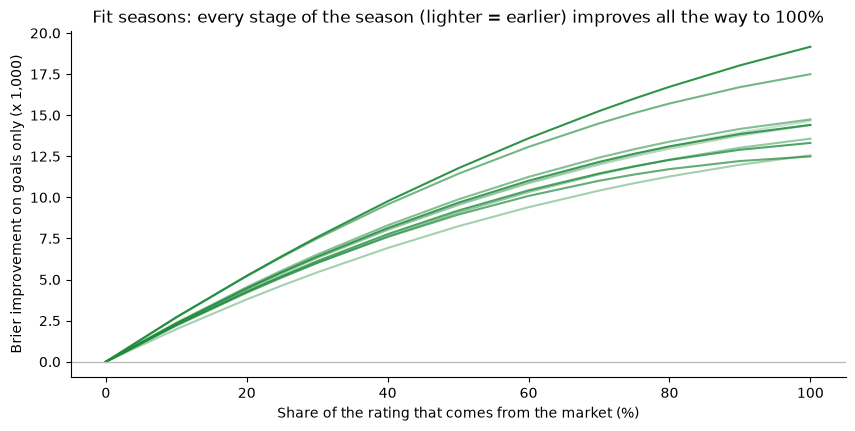

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for label, row in by_stage.iterrows():
    v = row[[f"{int(round(100 * w))}%" for w in WEIGHTS]].to_numpy(dtype=float)
    ax.plot(100 * WEIGHTS, 1000 * (v[0] - v), color=GREEN, alpha=0.25 + 0.075 * list(by_stage.index).index(label))
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel("Share of the rating that comes from the market (%)"); ax.set_ylabel("Brier improvement on goals only (x 1,000)")
ax.set_title("Fit seasons: every stage of the season (lighter = earlier) improves all the way to 100%")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

**No.** At every stage, from the first weeks to the last, every extra 10% of market helps and 100% is best. So there's no falling share to fit: a straight line from "share at the start" to "share at the end", chosen on the fit seasons, comes out as 100% at both ends.

**The test seasons**, judged with nothing changed:

In [11]:
def summary(d):
    return pd.DataFrame({f"{int(100 * w)}% market": {"Brier": d[f"brier{int(round(100 * w))}"].mean(), "log loss": d[f"ll{int(round(100 * w))}"].mean()}
                         for w in (0.0, 0.25, 0.5, 0.75, 1.0)}).T.round(4)

def paired_ci(d, a, b, B=2000, seed=0):
    # mean of (Brier at share a) minus (Brier at share b), resampling whole matches
    diff = (d[f"brier{a}"] - d[f"brier{b}"]).to_numpy()
    _, g = np.unique(d["match"], return_inverse=True)
    sums, counts = np.bincount(g, diff), np.bincount(g)
    rng = np.random.default_rng(seed)
    boot = [sums[i].sum() / counts[i].sum() for i in (rng.integers(0, len(sums), len(sums)) for _ in range(B))]
    return diff.mean(), np.percentile(boot, [2.5, 97.5])

print("FIT SEASONS"); display(summary(fit))
print("TEST SEASONS"); display(summary(test))
est, (lo, hi) = paired_ci(test, 100, 25)
print(f"TEST, 100% market minus 25% (the old live share): Brier {est:+.4f} (95% CI {lo:+.4f} to {hi:+.4f})")
gap = (test["brier0"].mean() - test["brier100"].mean()) / (test["brier0"].mean() - test["brier_market"].mean())
print(f"The bookmakers' own pre-match prices on the same test matches: Brier {test['brier_market'].mean():.4f}. "
      f"100% market closes {gap:.0%} of the gap between goals only and the bookmakers.")

FIT SEASONS


,Brier,log loss
0% market,0.6070,1.0138
25% market,0.6017,1.0057
50% market,0.5977,0.9996
75% market,0.5947,0.9953
100% market,0.5929,0.9926


TEST SEASONS


,Brier,log loss
0% market,0.6096,1.0177
25% market,0.6048,1.0105
50% market,0.6014,1.0054
75% market,0.5992,1.0021
100% market,0.5982,1.0006


TEST, 100% market minus 25% (the old live share): Brier -0.0066 (95% CI -0.0092 to -0.0040)
The bookmakers' own pre-match prices on the same test matches: Brier 0.5884. 100% market closes 54% of the gap between goals only and the bookmakers.


**Where does the gain come from?** The improvement of 100% market over goals only on the test seasons, by how far into the season the forecast was made (Brier x 1,000):

In [12]:
fifths = pd.cut(test["stage"], [0, .2, .4, .6, .8, 1.01], labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])
gain = (1000 * (test["brier0"] - test["brier100"])).groupby(fifths, observed=True).agg(["mean", "size"]).round(1)
gain.columns = ["Brier improvement (x 1,000)", "forecasts"]
gain

,"Brier improvement (x 1,000)",forecasts
stage,,
0-20%,15.0,12957
20-40%,9.3,10505
40-60%,9.6,7222
60-80%,8.2,3556
80-100%,10.4,899


Biggest in the first weeks, when the goal ratings rest on a handful of games, and roughly the same for the rest of the season.


**By league**, on the test seasons:

In [13]:
by_league = test.groupby("league")[[f"brier{int(round(100 * w))}" for w in (0.0, 0.25, 0.5, 0.75, 1.0)]].mean()
by_league.columns = ["0%", "25%", "50%", "75%", "100%"]
by_league["best"] = by_league.idxmin(axis=1)
by_league["100% vs 25% (x 1,000)"] = (1000 * (by_league["25%"] - by_league["100%"])).round(1)
by_league.round(4)

,0%,25%,50%,75%,100%,best,"100% vs 25% (x 1,000)"
league,,,,,,,
bundesliga_germany,0.6012,0.5963,0.5922,0.5890,0.5866,100%,9.7
championship_england,0.6469,0.6419,0.6383,0.6359,0.6345,100%,7.4
eredivisie_netherlands,0.6183,0.6132,0.6093,0.6065,0.6047,100%,8.5
laliga_spain,0.5883,0.5841,0.5812,0.5794,0.5786,100%,5.5
ligue1_france,0.6312,0.6232,0.6165,0.6110,0.6067,100%,16.5
premierleague_england,0.6430,0.6374,0.6332,0.6301,0.6282,100%,9.2
primeiraliga_portugal,0.5701,0.5649,0.5606,0.5573,0.5550,100%,9.9
seriea_brazil,0.5925,0.5887,0.5871,0.5876,0.5900,50%,-1.3
seriea_italy,0.5897,0.5871,0.5854,0.5845,0.5844,100%,2.7


In [14]:
bf = fit[fit["league"] == "seriea_brazil"]
print("Brazil, fit seasons:", {f"{int(round(100 * w))}%": round(bf[f"brier{int(round(100 * w))}"].mean(), 4) for w in (0.0, 0.25, 0.5, 0.75, 1.0)})

Brazil, fit seasons: {'0%': 0.6397, '25%': 0.6331, '50%': 0.6285, '75%': 0.6255, '100%': 0.6242}


100% is best in eight of nine. Brazil is the exception, where 50% did slightly better, but on its fit seasons 100% was clearly best there too (see the fit-season check below), so I'm treating it as noise rather than a reason for a Brazil-only setting.

**Is it the price timing?** The same end-of-2025/26 stretch as the October test, with a price counting as known 1, 3, or 7 days before kick-off (same target matches every time):

In [15]:
def lead_check(lead):
    global PRICE_LEAD_DAYS
    PRICE_LEAD_DAYS = lead; _fd.clear()
    sc = {w: [] for w in (0.0, 0.5, 1.0)}
    for lg in LEAGUES8[:-1]:
        cur = fd(lg, 2025)
        for D in pd.date_range("2026-03-10 10:00", "2026-05-19 10:00", freq="7D"):
            r, _ = ratings_as_of(lg, 2025, D)
            fut = cur[(cur["utcDate"] > D + pd.Timedelta(days=7)) & (cur["utcDate"] <= D + pd.Timedelta(days=28)) & cur["homeGoals"].notna()]
            if r["attack_market"] is None or fut.empty:
                continue
            y = np.eye(3)[np.where(fut["homeGoals"] > fut["awayGoals"], 0, np.where(fut["homeGoals"] == fut["awayGoals"], 1, 2))]
            for w in sc:
                a = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], w); d = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], w)
                sc[w].append(((probs(a, d, r["league_avg"], r["home_adv"], fut["homeTeam"].to_numpy(), fut["awayTeam"].to_numpy()) - y) ** 2).sum(1))
    return {f"{int(100 * w)}% market": np.concatenate(v).mean() for w, v in sc.items()}

lead_table = pd.DataFrame({f"known {k} days before": lead_check(k) for k in (1, 3, 7)}).T.round(4)
PRICE_LEAD_DAYS = 7; _fd.clear()
lead_table

,0% market,50% market,100% market
known 1 days before,0.6168,0.6107,0.6085
known 3 days before,0.6168,0.6108,0.6087
known 7 days before,0.6168,0.6104,0.6080


Same answer whichever way: 100% market is best, so it isn't fresher information sneaking in.

### 6. Does the market make far-away games too certain?

The worry: market prices react to short-term things (an injury, a suspension), so ratings built on them could make a match months away look more certain than it is. Two checks on the test seasons, by how far ahead the match was: the scores, and how often the favourite actually won against how likely it was said to be.

In [16]:
dist = pd.cut(test["days"], [0, 14, 28, 56, 112, 400], labels=["1-2 weeks", "2-4 weeks", "4-8 weeks", "8-16 weeks", "16+ weeks"])
rows = []
for label, d in test.groupby(dist, observed=True):
    for w in (0.0, 0.25, 1.0):
        P = np.stack(d[f"p{int(round(100 * w))}"])
        rows.append({"distance": label, "market": f"{int(100 * w)}%", "forecasts": len(d), "Brier": d[f"brier{int(round(100 * w))}"].mean(),
                     "favourite's chance": P.max(1).mean(), "favourite won": (P.argmax(1) == d["y"].to_numpy()).mean()})
certainty = pd.DataFrame(rows).set_index(["distance", "market"])
certainty["gap"] = certainty["favourite's chance"] - certainty["favourite won"]
certainty.round(3)

forecasts  Brier  favourite's chance  favourite won    gap
distance   market                                                            
1-2 weeks  0%           2215  0.602               0.541          0.510  0.031
           25%          2215  0.597               0.533          0.510  0.023
           100%         2215  0.591               0.513          0.521 -0.008
2-4 weeks  0%           3721  0.605               0.542          0.511  0.031
           25%          3721  0.600               0.534          0.518  0.016
           100%         3721  0.592               0.513          0.522 -0.009
4-8 weeks  0%           6613  0.606               0.541          0.509  0.033
           25%          6613  0.601               0.533          0.515  0.018
           100%         6613  0.594               0.511          0.522 -0.011
8-16 weeks 0%          10106  0.609               0.541          0.496  0.044
           25%         10106  0.605               0.533          0.503  0.030
           100%        10106  0.598               0.512          0.511  0.001
16+ weeks  0%          12484  0.614               0.532          0.488  0.043
           25%         12484  0.610               0.526          0.491  0.035
           100%        12484  0.604               0.511          0.495  0.016

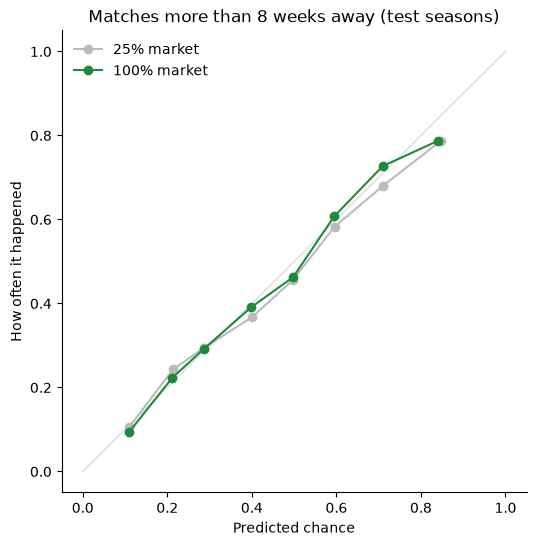

In [17]:
far = test[test["days"] > 56]
fig, ax = plt.subplots(figsize=(6, 6))
for w, colour, label in [(0.25, GREY, "25% market"), (1.0, GREEN, "100% market")]:
    p, o = np.stack(far[f"p{int(round(100 * w))}"]).ravel(), np.eye(3)[far["y"]].ravel()
    b = pd.DataFrame({"p": p, "o": o}).groupby(pd.cut(p, [0, .15, .25, .35, .45, .55, .65, .8, 1]), observed=True).mean()
    ax.plot(b["p"], b["o"], "o-", color=colour, label=label)
ax.plot([0, 1], [0, 1], color="#DDDDDD", lw=1, zorder=0)
ax.set_xlabel("Predicted chance"); ax.set_ylabel("How often it happened"); ax.legend(frameon=False)
ax.set_title("Matches more than 8 weeks away (test seasons)")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

**It's the other way round.** Every model gets a little worse the further ahead it looks, which is expected. But at every distance the market-based ratings are **less** confident than the goals-based ones, and closer to how often favourites actually win. The overconfidence comes from the goal ratings: with 25% market, favourites 16+ weeks away were given more than they won.

### 7. Final thoughts

* **The October result was the bug.** Fewer than 1% of the saved prices were taken mid-game, but they're extreme and they're the ones the ratings use. With them removed, the market helps at the end of a season too.
* **On four seasons of clean odds, 100% market is best at every stage of the season,** in all nine leagues on the fit seasons and eight of nine on the test seasons, by a clear margin over the old 25%.
* **No extra certainty far ahead.** Market-based forecasts are slightly *less* confident, and better calibrated, at every distance.
* **The goals model doesn't disappear.** It still sets the strength of a team the market has barely priced (the ridge pulls the market fit towards it), provides the league's scoring level and home advantage, and stands in whenever there are no odds.

That's what's live now: `MARKET_WEIGHT = 1.0` in `3_probabilities.py`, and in-play prices are no longer saved.